In [24]:
from joblib import load
import sys
import pandas as pd
import glob
import numpy as np
sys.path.append('/data/Phillippy/projects/pickettbd_data/parent-of-origin/pofo_tools/src/')
sys.path.append('/data/Phillippy/projects/pickettbd_data/parent-of-origin/pofo_tools/src/')
# import pofo_tools
import pickle
from tqdm import tqdm
import time
# from pofo_tools.utils import *
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
import seaborn as sns
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)

from pybedtools import BedTool
from scipy.stats import fisher_exact
import matplotlib.pyplot as plt
from matplotlib_venn import venn2, venn3


## READ INPUT FILES

In [25]:
idmr = BedTool('/path/to/project/pooch//findings/Imprinted_DMR_List_V1.LiftedOverToT2T-CHM13v2Hs1.bed') 
idmr.head()

chr1	11044370	11044544	Maternal	PTCHD2	Hernandez
 chr1	21120031	21120143	Maternal	ECE1;LOC100506801	Hernandez
 chr1	32329102	32329320	Maternal	ZBTB8B	Joshi
 chr1	39384177	39384444	Maternal	BMP8A	Akbari
 chr1	39427318	39428447	Maternal	PPIEL,PABPC4	Akbari,Court,Hernandez,Joshi,Zink
 chr1	67924206	67929467	Maternal	DIRAS3,DIRAS3_Ex2,GNG12-AS1	Akbari,Court,Hernandez,Joshi,Zink
 chr1	176387296	176387476	Maternal	ASTN1	Zink
 chr1	227504793	227504903	Maternal	OBSCN	Joshi
 chr10	13172944	13173273	Maternal	BTBD7P1	Akbari
 chr10	27443798	27444893	Maternal	PTCHD3	Akbari,Hernandez
 

  chrom     start       end parentoforigin               gene        ref  len
0  chr1  11044370  11044544       Maternal             PTCHD2  Hernandez  174
1  chr1  21120031  21120143       Maternal  ECE1;LOC100506801  Hernandez  112
Median : 866
Mean : 2151


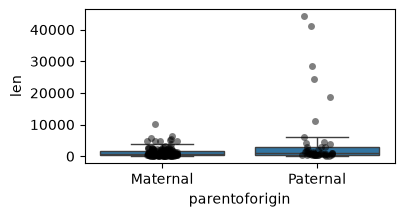

In [26]:
idmr_df = pd.read_csv('/path/to/project/pooch//findings/Imprinted_DMR_List_V1.LiftedOverToT2T-CHM13v2Hs1.bed', header = None, sep = "\t")
idmr_df.columns = ["chrom", "start", "end", "parentoforigin", "gene", "ref"]
idmr_df['len'] = idmr_df['end'] - idmr_df['start']

print(idmr_df.head(2))

plt.figure(figsize=(4,2))
sns.boxplot(x = "parentoforigin", y = "len", data = idmr_df, showfliers = False)
sns.stripplot(x = "parentoforigin", y = "len", data = idmr_df, color = "black", alpha = 0.5)

print(f"Median : {np.median(idmr_df['len']).astype(int)}")
print(f"Mean : {np.mean(idmr_df['len']).astype(int)}")

In [27]:
model_files = glob.glob('/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/07.models_selection_using_fdr_balance_X_n46_xist_slope_adjust/*.pkl')

import cloudpickle
sys.modules['joblib.externals.cloudpickle'] = cloudpickle


def chromosome_from_model_file(model_file):
    filename = model_file.split('/')[-1]
    if filename.startswith('elasticnet_bestmodel_'):
        return filename.split('elasticnet_bestmodel_')[1].split('.')[0]
    return filename.split('.')[0]


def load_final_elasticnet_coef(model_file):
    with open(model_file, 'rb') as f:
        obj = pickle.load(f)

    pipe = obj['pipeline'] if isinstance(obj, dict) else obj
    model = pipe.named_steps['model']

    if 'select' in pipe.named_steps and hasattr(pipe.named_steps['select'], 'selected_cpg_names_'):
        features = pipe.named_steps['select'].selected_cpg_names_
    else:
        features = model.feature_names_in_

    return np.asarray(features).astype(int), model.coef_.flatten()


coef_df = pd.DataFrame()
chromosome_list = []
for model_file in tqdm(model_files):
    chr = chromosome_from_model_file(model_file)
    features, coef = load_final_elasticnet_coef(model_file)
    coef_tmp_df = pd.DataFrame({
        'feature': features,
        'coefficient': coef
    })
    coef_tmp_df['feature_MB'] = coef_tmp_df['feature'] / 1e+06
    coef_tmp_df['chr'] = chr
    coef_df = pd.concat([coef_df, coef_tmp_df], axis=0)
    chromosome_list.append(chr)

print(f"chromosome : {chromosome_list}")

coef_df['id'] = coef_df['chr'] + ":" + coef_df['feature'].astype(str)
coef_df = coef_df.loc[coef_df['coefficient'] != 0]
coef_df.head()


  0%|          | 0/23 [00:00<?, ?it/s]/weka/home/jhu/jkim789/miniforge3/envs/python_plot/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SelectFdr from version 1.5.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/weka/home/jhu/jkim789/miniforge3/envs/python_plot/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.5.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/weka/home/jhu/jkim789/miniforge3/envs/python_plot/lib/python3.11/site-packages/sklearn/base.py:5

chromosome : ['chr17', 'chr18', 'chr16', 'chr11', 'chr5', 'chr3', 'chr6', 'chr20', 'chr9', 'chr1', 'chr21', 'chr15', 'chr19', 'chr14', 'chr12', 'chr10', 'chr7', 'chr2', 'chr22', 'chr13', 'chr4', 'chr8', 'chrX']


,feature,coefficient,feature_MB,chr,id
81,253866,-0.036325,0.253866,chr17,chr17:253866
82,253916,-0.142628,0.253916,chr17,chr17:253916
105,331605,0.199078,0.331605,chr17,chr17:331605
106,331611,0.133057,0.331611,chr17,chr17:331611
107,331636,0.380619,0.331636,chr17,chr17:331636


In [28]:
len(coef_df['chr'].unique())

23

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22],
 [Text(0, 0, 'chr1'),
  Text(1, 0, 'chr10'),
  Text(2, 0, 'chr11'),
  Text(3, 0, 'chr12'),
  Text(4, 0, 'chr13'),
  Text(5, 0, 'chr14'),
  Text(6, 0, 'chr15'),
  Text(7, 0, 'chr16'),
  Text(8, 0, 'chr17'),
  Text(9, 0, 'chr18'),
  Text(10, 0, 'chr19'),
  Text(11, 0, 'chr2'),
  Text(12, 0, 'chr20'),
  Text(13, 0, 'chr21'),
  Text(14, 0, 'chr22'),
  Text(15, 0, 'chr3'),
  Text(16, 0, 'chr4'),
  Text(17, 0, 'chr5'),
  Text(18, 0, 'chr6'),
  Text(19, 0, 'chr7'),
  Text(20, 0, 'chr8'),
  Text(21, 0, 'chr9'),
  Text(22, 0, 'chrX')])

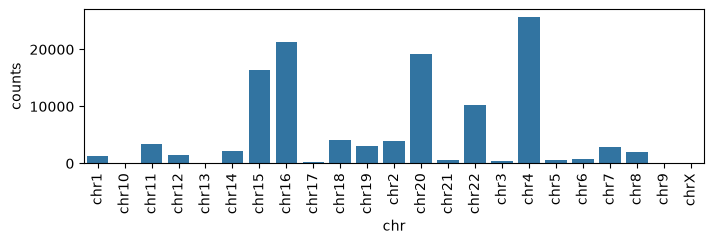

In [29]:
plt.figure(figsize=(8,2))
sns.barplot(data=coef_df.groupby('chr').size().reset_index(name='counts').sort_values(by='chr', ascending=True), x='chr', y='counts')
plt.xticks(rotation=90)

In [30]:
# how to read the first 1 line
total_cpg_df = pd.DataFrame()
for chromosome in tqdm(chromosome_list):
    # print(chromosome)
    # total_cpg = pd.read_csv(f"/vf/users/Phillippy/projects/pooch_snakemake/pooch_data/07.models_selection_using_fdr/{chromosome}.missingrate_5.createDiffDatasetFromMethylDataset.out", header=None, nrows=1, sep = "\t").iloc[:,3:].T
    filename = f"/path/to/project/pooch/pooch_data/07.models_using_DSS_insideCV/{chromosome}.missingrate_5.createDiffDatasetFromMethylDataset.out"
    with open(filename) as f:
        total_cpg = f.readline().rstrip("\n").split("\t")[3:]
    total_cpg = pd.DataFrame(total_cpg, columns=['feature'])
    total_cpg['chr'] = chromosome
    total_cpg_df = pd.concat([total_cpg_df, total_cpg], axis=0)

total_cpg_df['id'] = total_cpg_df['chr'] + ":" + total_cpg_df['feature'].astype(str)
total_cpg_df.head(2)

100%|██████████| 23/23 [00:22<00:00,  1.04it/s]


,feature,chr,id
0,1149,chr17,chr17:1149
1,5517,chr17,chr17:5517


In [31]:
dss_bed= BedTool("/path/to/project/pooch/pooch_data/05.dss_using_123_pairing/dmrs.N05_filt.all_chr.1e3.mrg.forPlotting.bed.gz")


In [32]:
len(total_cpg_df['chr'].unique())

23

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22],
 [Text(0, 0, 'chr1'),
  Text(1, 0, 'chr10'),
  Text(2, 0, 'chr11'),
  Text(3, 0, 'chr12'),
  Text(4, 0, 'chr13'),
  Text(5, 0, 'chr14'),
  Text(6, 0, 'chr15'),
  Text(7, 0, 'chr16'),
  Text(8, 0, 'chr17'),
  Text(9, 0, 'chr18'),
  Text(10, 0, 'chr19'),
  Text(11, 0, 'chr2'),
  Text(12, 0, 'chr20'),
  Text(13, 0, 'chr21'),
  Text(14, 0, 'chr22'),
  Text(15, 0, 'chr3'),
  Text(16, 0, 'chr4'),
  Text(17, 0, 'chr5'),
  Text(18, 0, 'chr6'),
  Text(19, 0, 'chr7'),
  Text(20, 0, 'chr8'),
  Text(21, 0, 'chr9'),
  Text(22, 0, 'chrX')])

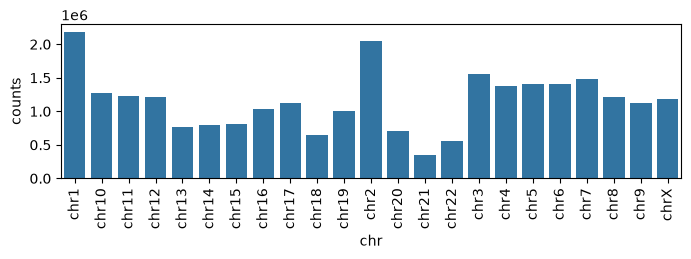

In [33]:
# total_cpg_df.groupby('chr').size().reset_index(name='counts')

plt.figure(figsize=(8,2))
sns.barplot(data=total_cpg_df.groupby('chr').size().reset_index(name='counts'), x='chr', y='counts')
plt.xticks(rotation=90)

In [34]:
dss = pd.DataFrame()
#for chromosome in tqdm(chromosome_list):
#    filename = f"/path/to/project/pooch/pooch_data/05.dss_using_123_pairing/dmls.N05_filt.{chromosome}.csv"
#    dss_tmp = pd.read_csv(filename, header=0, sep="\t")
#    dss = pd.concat([dss, dss_tmp], axis=0)
dss = pd.read_csv("/path/to/project/pooch/pooch_data/05.dss_using_123_pairing/dmls.N05_filt.allChr.1e3.csv",
                  sep ='\t',header = None)
dss.columns = ['chr','pos','stat','pvals','fdrs']
dss.head(2)
dss['id']=dss['chr'] + ":" + dss['pos'].astype(str)
dss['-logp'] = -np.log10(dss['fdrs'] + 1e-10)  # add a small value to avoid log(0)
dss.head(2)

,chr,pos,stat,pvals,fdrs,id,-logp
0,chr1,2116825,-6.046281,1.482271e-09,0.000013,chr1:2116825,4.895968
1,chr1,2116827,-5.904482,3.537560e-09,0.000030,chr1:2116827,4.530093


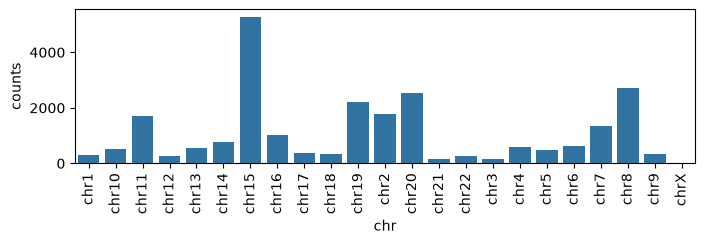

In [35]:
dss_count = dss.groupby('chr').size().reset_index(name='counts')

plt.figure(figsize=(8,2))
sns.barplot(data=dss_count, x='chr', y='counts')
plt.xticks(rotation=90)
plt.show()

In [36]:
len(dss['chr'].unique())

23

## CALCULATE FISHER'S TEST

### between dss dmls and model-selected CpGs

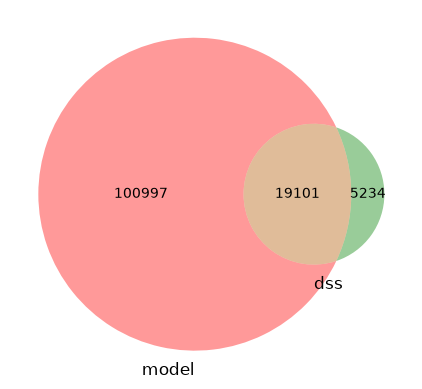

In [37]:
# total_cpg_ids = set(total_cpg_df.loc[total_cpg_df['chr'] != "chrX", 'id'])
# model_selected_ids = set(coef_df.loc[(coef_df['coefficient'] != 0) & (coef_df['chr'] != "chrX"), 'id']) & total_cpg_ids

total_cpg_ids = set(total_cpg_df['id'])
model_selected_ids = set(coef_df.loc[(coef_df['coefficient'] != 0), 'id']) & total_cpg_ids
dss_sig_ids = set(dss['id']) & total_cpg_ids

venn2([model_selected_ids, dss_sig_ids], 
      set_labels=("model", "dss"))

plt.savefig("/path/to/project/pooch//figures/fisher_test/VennDiagram1.pdf", bbox_inches='tight')
plt.show()

In [38]:
a = len(dss_sig_ids & model_selected_ids)            # DSS-sig & model-selected
c = len(model_selected_ids - dss_sig_ids)            # not DSS-sig & model-selected
b = len(dss_sig_ids - model_selected_ids)            # DSS-sig & not model-selected
d = len(total_cpg_ids - (dss_sig_ids | model_selected_ids))  # not DSS-sig & not model-selected

table = [[a, b], [c, d]]
# Fisher's exact test
odds_ratio, p_value = fisher_exact(table, alternative="two-sided")

# 95% CI for odds ratio
log_or = np.log(odds_ratio)
se_log_or = np.sqrt(1/a + 1/b + 1/c + 1/d)

z = 1.96
ci_lower = np.exp(log_or - z * se_log_or)
ci_upper = np.exp(log_or + z * se_log_or)

# Selection rates
dss_sig_rate = a / (a + b)
not_dss_sig_rate = c / (c + d)

# Print results
print("Contingency table:")
print(pd.DataFrame(
    table,
    index=["DSS-sig", "not DSS-sig"],
    columns=["model-selected", "not model-selected"]
))

print(f"\nDSS-sig selection rate     = {dss_sig_rate:.4%}")
print(f"not DSS-sig selection rate = {not_dss_sig_rate:.4%}")

print(f"\nOdds ratio = {odds_ratio:.3f}")
print(f"95% CI     = ({ci_lower:.3f}, {ci_upper:.3f})")
print(f"p-value    = {p_value:.3e}")

Contingency table:
             model-selected  not model-selected
DSS-sig               19101                5234
not DSS-sig          100997            26373116

DSS-sig selection rate     = 78.4919%
not DSS-sig selection rate = 0.3815%

Odds ratio = 952.962
95% CI     = (923.691, 983.160)
p-value    = 0.000e+00


In [39]:
# Selection rates
dss_sig_rate = a / (a + c)
not_dss_sig_rate = b / (b + d)

# Print results
print("Contingency table:")
print(pd.DataFrame(
    table,
    index=["DSS-sig", "not DSS-sig"],
    columns=["model-selected", "not model-selected"]
))

print(f"\nDSS-sig selection rate     = {dss_sig_rate:.4%}")
print(f"not DSS-sig selection rate = {not_dss_sig_rate:.4%}")

print(f"\nOdds ratio = {odds_ratio:.3f}")
print(f"95% CI     = ({ci_lower:.3f}, {ci_upper:.3f})")
print(f"p-value    = {p_value:.3e}")

Contingency table:
             model-selected  not model-selected
DSS-sig               19101                5234
not DSS-sig          100997            26373116

DSS-sig selection rate     = 15.9045%
not DSS-sig selection rate = 0.0198%

Odds ratio = 952.962
95% CI     = (923.691, 983.160)
p-value    = 0.000e+00


In [40]:
print(f"total cpg : {a + b + c + d}")

total cpg : 26498448


In [41]:
table

[[19101, 5234], [100997, 26373116]]

In [42]:
table= pd.DataFrame(
    table,
    index=["DSS-sig", "not DSS-sig"],
    columns=["model-selected", "not model-selected"]
)
table

,model-selected,not model-selected
DSS-sig,19101,5234
not DSS-sig,100997,26373116


/tmp/ipykernel_2303666/3269781000.py:18: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


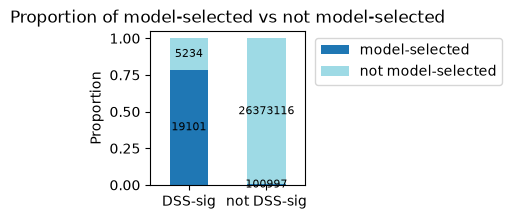

In [43]:
# stack bar plot of proportion
table_prop = table.div(table.sum(axis=1), axis=0)

ax = table_prop.plot(kind="bar", stacked=True, figsize=(2, 2), colormap="tab20")
ax.set_ylabel("Proportion")
ax.set_xlabel("")
ax.set_title("Proportion of model-selected vs not model-selected")
ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc="upper left")
for p in ax.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy() 
    bar_index = round(x + width / 2)
    bar_total = table.sum(axis=1).iloc[bar_index]
    count = round(height * bar_total)
    ax.annotate(f'{count}', (x + width/2, y + height/2), ha='center', va='center', fontsize=8, color='black')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("/path/to/project/pooch//figures/fisher_test/stacked_bar_plot1.pdf", bbox_inches='tight')
plt.show()

/tmp/ipykernel_2303666/3789441569.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


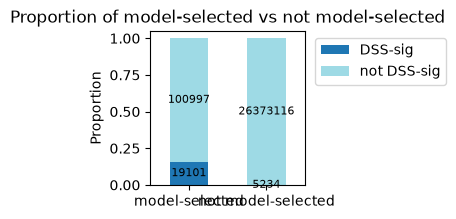

In [44]:
# stack bar plot of proportion
table_prop = table.T.div(table.T.sum(axis=1), axis=0)

ax = table_prop.plot(kind="bar", stacked=True, figsize=(2, 2), colormap="tab20")
ax.set_ylabel("Proportion")
ax.set_xlabel("")
ax.set_title("Proportion of model-selected vs not model-selected")
ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc="upper left")
# Add real number label 
for p in ax.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy() 
    bar_index = round(x + width / 2)
    bar_total = table.sum(axis=0).iloc[bar_index]
    count = round(height * bar_total)
    ax.annotate(f'{count}', (x + width/2, y + height/2), ha='center', va='center', fontsize=8, color='black')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("/path/to/project/pooch//figures/fisher_test/stacked_bar_plot2.pdf", bbox_inches='tight')
plt.show()


In [45]:
# chi square test

from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(table)

print(f"Chi-square = {chi2:.3f}")
print(f"p-value = {p_value:.3e}")
print(f"df = {dof}")

print("\nExpected counts:")
print(expected)

Chi-square = 3287642.278
p-value = 0.000e+00
df = 1

Expected counts:
[[1.10292679e+02 2.42247073e+04]
 [1.19987707e+05 2.63541253e+07]]


### known iDMR vs model selected

In [46]:
# build a BED of all measured CpGs (background) and flag which fall inside iDMRs
in_idmr = total_cpg_df[['chr', 'feature']].drop_duplicates().copy()
in_idmr['feature'] = in_idmr['feature'].astype(int)
in_idmr['start'] = in_idmr['feature']
in_idmr['end'] = in_idmr['feature'] 
in_idmr_bed = BedTool.from_dataframe(in_idmr[['chr', 'start', 'end']]).sort()

in_idmr_ids = {f"{f.chrom}:{f.start}" for f in in_idmr_bed.intersect(idmr, u=True)}

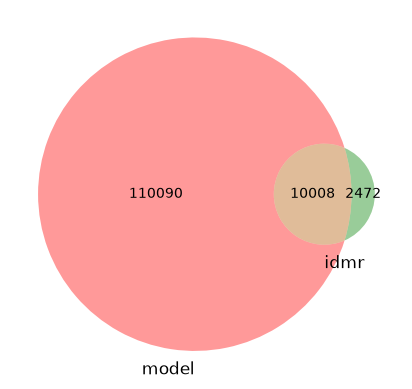

In [47]:
venn2([model_selected_ids, in_idmr_ids], 
      set_labels=("model", "idmr"))
plt.savefig("/path/to/project/pooch//figures/fisher_test/Venndiagram2.pdf", bbox_inches='tight')
plt.show()

In [48]:
a = len(model_selected_ids & in_idmr_ids)                  # selected & in iDMR
c = len(model_selected_ids - in_idmr_ids)                  # selected & not in iDMR
b = len(in_idmr_ids - model_selected_ids)                  # not selected & in iDMR
d = len(total_cpg_ids - (in_idmr_ids | model_selected_ids))  # not selected & not in iDMR

idmr_table = [[a, b], [c, d]]
odds_ratio, p_value = fisher_exact(idmr_table, alternative="two-sided")

# 95% CI for odds ratio
log_or = np.log(odds_ratio)
# se_log_or = np.sqrt(1/a + 1/b + 1/c + 1/d)

# z = 1.96
# ci_lower = np.exp(log_or - z * se_log_or)
# ci_upper = np.exp(log_or + z * se_log_or)

# Selection rates
idmr_rate = a / (a + b)
not_idmr_rate = c / (c + d)

# Print results
print("Contingency table:")
print(pd.DataFrame(
    idmr_table,
    index=["in iDMR", "not in iDMR"],
    columns=["model-selected", "not model-selected"]
))

print(f"\niDMR selection rate     = {idmr_rate:.4%}")
print(f"not in iDMR selection rate = {not_idmr_rate:.4%}")

print(f"\nOdds ratio = {odds_ratio:.3f}")
# print(f"95% CI     = ({ci_lower:.3f}, {ci_upper:.3f})")
print(f"p-value    = {p_value:.3e}")

Contingency table:
             model-selected  not model-selected
in iDMR               10008                2472
not in iDMR          110090            26375878

iDMR selection rate     = 80.1923%
not in iDMR selection rate = 0.4157%

Odds ratio = 969.969
p-value    = 0.000e+00


In [49]:
# Selection rates
idmr_rate = a / (a + c)
not_idmr_rate = c / (b + d)

# Print results
print("Contingency table:")
print(pd.DataFrame(
    idmr_table,
    index=["in iDMR", "not in iDMR"],
    columns=["model-selected", "not model-selected"]
))

print(f"\niDMR selection rate     = {idmr_rate:.4%}")
print(f"not in iDMR selection rate = {not_idmr_rate:.4%}")

print(f"\nOdds ratio = {odds_ratio:.3f}")
# print(f"95% CI     = ({ci_lower:.3f}, {ci_upper:.3f})")
print(f"p-value    = {p_value:.3e}")

Contingency table:
             model-selected  not model-selected
in iDMR               10008                2472
not in iDMR          110090            26375878

iDMR selection rate     = 8.3332%
not in iDMR selection rate = 0.4173%

Odds ratio = 969.969
p-value    = 0.000e+00


In [50]:
idmr_table = [[a, b], [c, d]]
odds_ratio, p_value = fisher_exact(idmr_table, alternative="two-sided")

print(odds_ratio, p_value)

969.9690655571302 0.0


In [51]:
idmr_table = [[a, b], [c, d]]
odds_ratio, p_value = fisher_exact(idmr_table, alternative="two-sided")
print(odds_ratio, p_value)

969.9690655571302 0.0


In [52]:
print(f"total cpg : {a + b + c + d}")

total cpg : 26498448


In [53]:
table= pd.DataFrame(
    idmr_table,
    index=["in-iDMR", "not in-iDMR"],
    columns=["model-selected", "not model-selected"]
)
table

,model-selected,not model-selected
in-iDMR,10008,2472
not in-iDMR,110090,26375878


/tmp/ipykernel_2303666/855011069.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


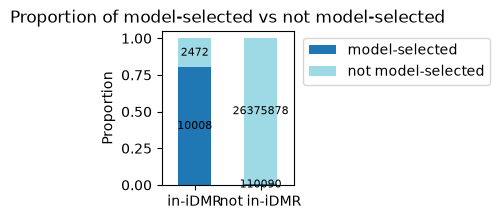

In [54]:
# stack bar plot of proportion
table_prop = table.div(table.sum(axis=1), axis=0)

ax = table_prop.plot(kind="bar", stacked=True, figsize=(1.7, 2), colormap="tab20")
ax.set_ylabel("Proportion")
ax.set_xlabel("")
ax.set_title("Proportion of model-selected vs not model-selected")
ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc="upper left")
# Add real number label 
for p in ax.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy() 
    bar_index = round(x + width / 2)
    bar_total = table.sum(axis=1).iloc[bar_index]
    count = round(height * bar_total)
    ax.annotate(f'{count}', (x + width/2, y + height/2), ha='center', va='center', fontsize=8, color='black')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("/path/to/project/pooch//figures/fisher_test/stacked_bar_plot3.pdf", bbox_inches='tight')
plt.show()

/tmp/ipykernel_2303666/1919837870.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


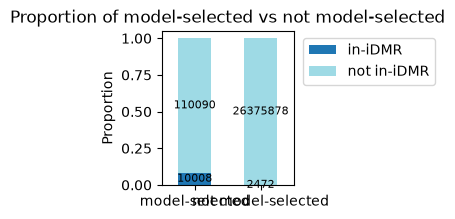

In [55]:
# stack bar plot of proportion
table_prop = table.T.div(table.T.sum(axis=1), axis=0)

ax = table_prop.plot(kind="bar", stacked=True, figsize=(1.7, 2), colormap="tab20")
ax.set_ylabel("Proportion")
ax.set_xlabel("")
ax.set_title("Proportion of model-selected vs not model-selected")
ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc="upper left")
# Add real number label 
for p in ax.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy() 
    bar_index = round(x + width / 2)
    bar_total = table.sum(axis=0).iloc[bar_index]
    count = round(height * bar_total)
    ax.annotate(f'{count}', (x + width/2, y + height/2), ha='center', va='center', fontsize=8, color='black')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("/path/to/project/pooch//figures/fisher_test/stacked_bar_plot4.pdf", bbox_inches='tight')
plt.show()

In [56]:
# build a BED of all measured CpGs (background) and flag which fall inside iDMRs
in_idmr = total_cpg_df[['chr', 'feature']].drop_duplicates().copy()
in_idmr['feature'] = in_idmr['feature'].astype(int)
in_idmr['start'] = in_idmr['feature'] 
in_idmr['end'] = in_idmr['feature'] + 1 
in_idmr_bed = BedTool.from_dataframe(in_idmr[['chr', 'start', 'end']]).sort()

in_idmr_ids = {f"{f.chrom}:{f.start}" for f in in_idmr_bed.intersect(dss_bed, u=True)}

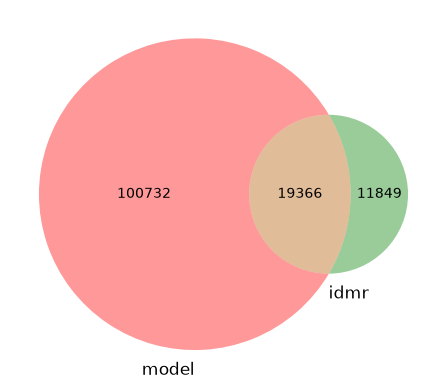

In [57]:
venn2([model_selected_ids, in_idmr_ids], 
      set_labels=("model", "idmr"))
plt.savefig("/path/to/project/pooch//figures/fisher_test/Venndiagram3.pdf", bbox_inches='tight')
plt.show()

In [58]:
a = len(model_selected_ids & in_idmr_ids)                  # selected & in iDMR
c = len(model_selected_ids - in_idmr_ids)                  # selected & not in iDMR
b = len(in_idmr_ids - model_selected_ids)                  # not selected & in iDMR
d = len(total_cpg_ids - (in_idmr_ids | model_selected_ids))  # not selected & not in iDMR

idmr_table = [[a, b], [c, d]]
odds_ratio, p_value = fisher_exact(idmr_table, alternative="two-sided")

# 95% CI for odds ratio
log_or = np.log(odds_ratio)
# se_log_or = np.sqrt(1/a + 1/b + 1/c + 1/d)

# z = 1.96
# ci_lower = np.exp(log_or - z * se_log_or)
# ci_upper = np.exp(log_or + z * se_log_or)

# Selection rates
idmr_rate = a / (a + b)
not_idmr_rate = c / (c + d)

# Print results
print("Contingency table:")
print(pd.DataFrame(
    idmr_table,
    index=["in iDMR", "not in iDMR"],
    columns=["model-selected", "not model-selected"]
))

print(f"\niDMR selection rate     = {idmr_rate:.4%}")
print(f"not in iDMR selection rate = {not_idmr_rate:.4%}")

print(f"\nOdds ratio = {odds_ratio:.3f}")
# print(f"95% CI     = ({ci_lower:.3f}, {ci_upper:.3f})")
print(f"p-value    = {p_value:.3e}")

Contingency table:
             model-selected  not model-selected
in iDMR               19366               11849
not in iDMR          100732            26366501

iDMR selection rate     = 62.0407%
not in iDMR selection rate = 0.3806%

Odds ratio = 427.802
p-value    = 0.000e+00


In [59]:
print(f"total cpg : {a + b + c + d}")

total cpg : 26498448


In [60]:
table= pd.DataFrame(
    idmr_table,
    index=["in-dssbed", "not in-dssbed"],
    columns=["model-selected", "not model-selected"]
)
table

,model-selected,not model-selected
in-dssbed,19366,11849
not in-dssbed,100732,26366501


/tmp/ipykernel_2303666/3958540442.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


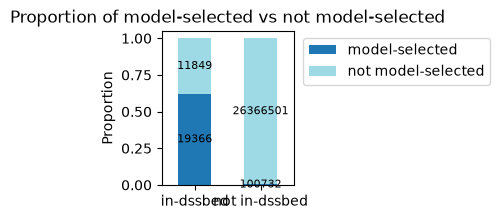

In [61]:
# stack bar plot of proportion
table_prop = table.div(table.sum(axis=1), axis=0)

ax = table_prop.plot(kind="bar", stacked=True, figsize=(1.7, 2), colormap="tab20")
ax.set_ylabel("Proportion")
ax.set_xlabel("")
ax.set_title("Proportion of model-selected vs not model-selected")
ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc="upper left")
# Add real number label 
for p in ax.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy() 
    bar_index = round(x + width / 2)
    bar_total = table.sum(axis=1).iloc[bar_index]
    count = round(height * bar_total)
    ax.annotate(f'{count}', (x + width/2, y + height/2), ha='center', va='center', fontsize=8, color='black')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("/path/to/project/pooch//figures/fisher_test/stacked_bar_plot5.pdf", bbox_inches='tight')
plt.show()

/tmp/ipykernel_2303666/1740015002.py:19: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


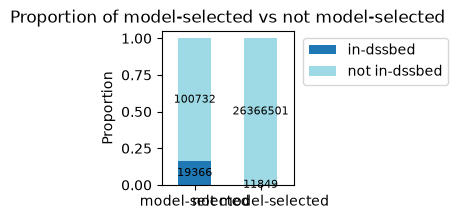

In [62]:
# stack bar plot of proportion
table_prop = table.T.div(table.T.sum(axis=1), axis=0)

ax = table_prop.plot(kind="bar", stacked=True, figsize=(1.7, 2), colormap="tab20")
ax.set_ylabel("Proportion")
ax.set_xlabel("")
ax.set_title("Proportion of model-selected vs not model-selected")
ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc="upper left")
# Add real number label 
for p in ax.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy() 
    bar_index = round(x + width / 2)
    bar_total = table.sum(axis=0).iloc[bar_index]
    count = round(height * bar_total)
    ax.annotate(f'{count}', (x + width/2, y + height/2), ha='center', va='center', fontsize=8, color='black')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("/path/to/project/pooch//figures/fisher_test/stacked_bar_plot6.pdf", bbox_inches='tight')
plt.show()